# Лабораторная работа №2: Полный блокнот (EDA & ML)
**Студент:** Мустафаев Музаффар
**Курс:** Введение в машинное обучение

В блокноте представлены все разделы: 1.1 (Исследование данных и предобработка) и 1.2 (Модели машинного обучения Scikit-learn и CatBoost).


### Задание 1.1.1. Имена столбцов и целевые классы
Отдельно для каждого из наборов данных (ФКГ — 3 файла, модуль позиционирования) получить имена столбцов. В описание к ответу вывести имена столбцов с названиями классов.


In [1]:
# Ответ на задание 1.1.1: Имена столбцов и целевые переменные
print("=== Набор ФКГ (Фонокардиограммы) ===")
print("Столбцы wave.csv:", list(df_wave.columns[:5]), "...", list(df_wave.columns[-5:]))
print("Столбцы envelope.csv:", list(df_env.columns[:5]), "...", list(df_env.columns[-5:]))
print("Столбцы wes.csv:", list(df_wes.columns[:5]), "...", list(df_wes.columns[-5:]))
print("Целевой столбец ФКГ: 'Type' (классы: wave, fS2, fS1, mom)")

print("\n=== Набор с модуля позиционирования ===")
print("Метаданные столбцов:", list(df_pos.columns[:9]))
print("Сигнальные параметры (ускорения):", list(df_pos.columns[9:14]), "...", list(df_pos.columns[-5:]))
print("Целевой столбец: 'class_type' (классы схватов 1-9)")


=== Набор ФКГ (Фонокардиограммы) ===
Столбцы wave.csv: ['RecordName', 'Start', 'Stop', 'Duration', 'Type'] ... ['wave181', 'wave182', 'wave183', 'wave184', 'wave185']
Столбцы envelope.csv: ['RecordName', 'Start', 'Stop', 'Duration', 'Type'] ... ['env181', 'env182', 'env183', 'env184', 'env185']
Столбцы wes.csv: ['RecordName', 'Start', 'Stop', 'Duration', 'Type'] ... ['wes181', 'wes182', 'wes183', 'wes184', 'wes185']
Целевой столбец ФКГ: 'Type' (классы: wave, fS2, fS1, mom)

=== Набор с модуля позиционирования ===
Метаданные столбцов: ['file_name', 'start', 'stop', 'duration', 'start_ms', 'stop_ms', 'duration_ms', 'samplerate', 'class_type']
Сигнальные параметры (ускорения): ['p_000', 'p_001', 'p_002', 'p_003', 'p_004'] ... ['p_3427', 'p_3428', 'p_3429', 'p_3430', 'p_3431']
Целевой столбец: 'class_type' (классы схватов 1-9)


### Задание 1.1.2. Количество категориальных и числовых параметров
По каждому из наборов в описании результата указать количество категориальных и числовых параметров.


In [2]:
# Ответ на задание 1.1.2: Подсчет категориальных и числовых параметров
cat_fkg = ['RecordName', 'Type']
num_fkg = [c for c in df_wave.columns if c not in cat_fkg]
print(f"ФКГ: {len(cat_fkg)} категориальных {cat_fkg}, {len(num_fkg)} числовых параметров.")

cat_pos = ['file_name']
num_pos = [c for c in df_pos.columns if c not in cat_pos]
print(f"Позиционирование: {len(cat_pos)} категориальных {cat_pos}, {len(num_pos)} числовых параметров.")


ФКГ: 2 категориальных ['RecordName', 'Type'], 189 числовых параметров.
Позиционирование: 1 категориальных ['file_name'], 3440 числовых параметров.


### Задание 1.1.3. Удаление незначимых столбцов
Удалить из открытых наборов данных столбцы, не относящиеся к значимым параметрам и наименованию классов.


In [3]:
# Ответ на задание 1.1.3: Удаление незначимых столбцов метаданных
clean_wave = df_wave.drop(columns=['RecordName', 'Start', 'Stop', 'Duration'])
clean_env = df_env.drop(columns=['RecordName', 'Start', 'Stop', 'Duration'])
clean_wes = df_wes.drop(columns=['RecordName', 'Start', 'Stop', 'Duration'])
clean_pos = df_pos.drop(columns=['file_name', 'start', 'stop', 'duration', 'start_ms', 'stop_ms', 'duration_ms', 'samplerate'])

print(f"ФКГ wave: {clean_wave.shape}, envelope: {clean_env.shape}, wes: {clean_wes.shape}")
print(f"Модуль позиционирования: {clean_pos.shape}")


ФКГ wave: (13179, 187), envelope: (13179, 187), wes: (13179, 187)
Модуль позиционирования: (14650, 3433)


### Задание 1.1.4. Преобразование категориальных классов в числовые
При необходимости перевести категориальные данные в числовые. Проверить наименования целевых классов и провести преобразования.


In [4]:
# Ответ на задание 1.1.4: Преобразование категориальных данных в числовые
le_fkg = LabelEncoder()
y_fkg_encoded = le_fkg.fit_transform(clean_wave['Type'])
print("Кодирование классов ФКГ:", {cls: int(idx) for idx, cls in enumerate(le_fkg.classes_)})

y_pos_encoded = clean_pos['class_type'] - 1
print("Классы схватов 1-9 приведены к диапазону 0-8.")


Кодирование классов ФКГ: {'fS1': 0, 'fS2': 1, 'mom': 2, 'wave': 3}
Классы схватов 1-9 приведены к диапазону 0-8.


### Задание 1.1.5. Соотношение классов в текстовом виде
По каждому из наборов вывести соотношения классов в текстовом виде в формате: «Класс 1»: N записей/паттернов.


In [5]:
# Ответ на задание 1.1.5: Вывод соотношения классов
print("=== Соотношение классов ФКГ ===")
for cls_name, count in fkg_counts.items():
    print(f"«Класс {cls_name}»: {count} записей/паттернов")

print("\n=== Соотношение классов модуля позиционирования ===")
for cls_id, count in pos_counts.items():
    print(f"«{pos_class_desc[cls_id - 1]}»: {count} записей/паттернов")


=== Соотношение классов ФКГ ===
«Класс wave»: 3409 записей/паттернов
«Класс fS2»: 3383 записей/паттернов
«Класс fS1»: 3310 записей/паттернов
«Класс mom»: 3077 записей/паттернов

=== Соотношение классов модуля позиционирования ===
«Схват 0 (Расслабленная рука)»: 6895 записей/паттернов
«Схват 1 (Кулак)»: 983 записей/паттернов
«Схват 2 (Прямая рука)»: 884 записей/паттернов
«Схват 3 (Отведение большого пальца)»: 976 записей/паттернов
«Схват 4 (Щипковый схват)»: 1023 записей/паттернов
«Схват 5 (Удержание карточки)»: 959 записей/паттернов
«Схват 6 (Удержание ручки)»: 1016 записей/паттернов
«Схват 7 (Удержание цилиндра)»: 951 записей/паттернов
«Схват 8 (Удержание мячика)»: 963 записей/паттернов


### Задание 1.1.6. Столбчатая диаграмма уникальных классов
Для каждого из наборов вывести в виде столбчатой диаграммы данные о количестве уникальных классов.


Диаграммы сохранены в outputs/fkg_classes_distribution.png


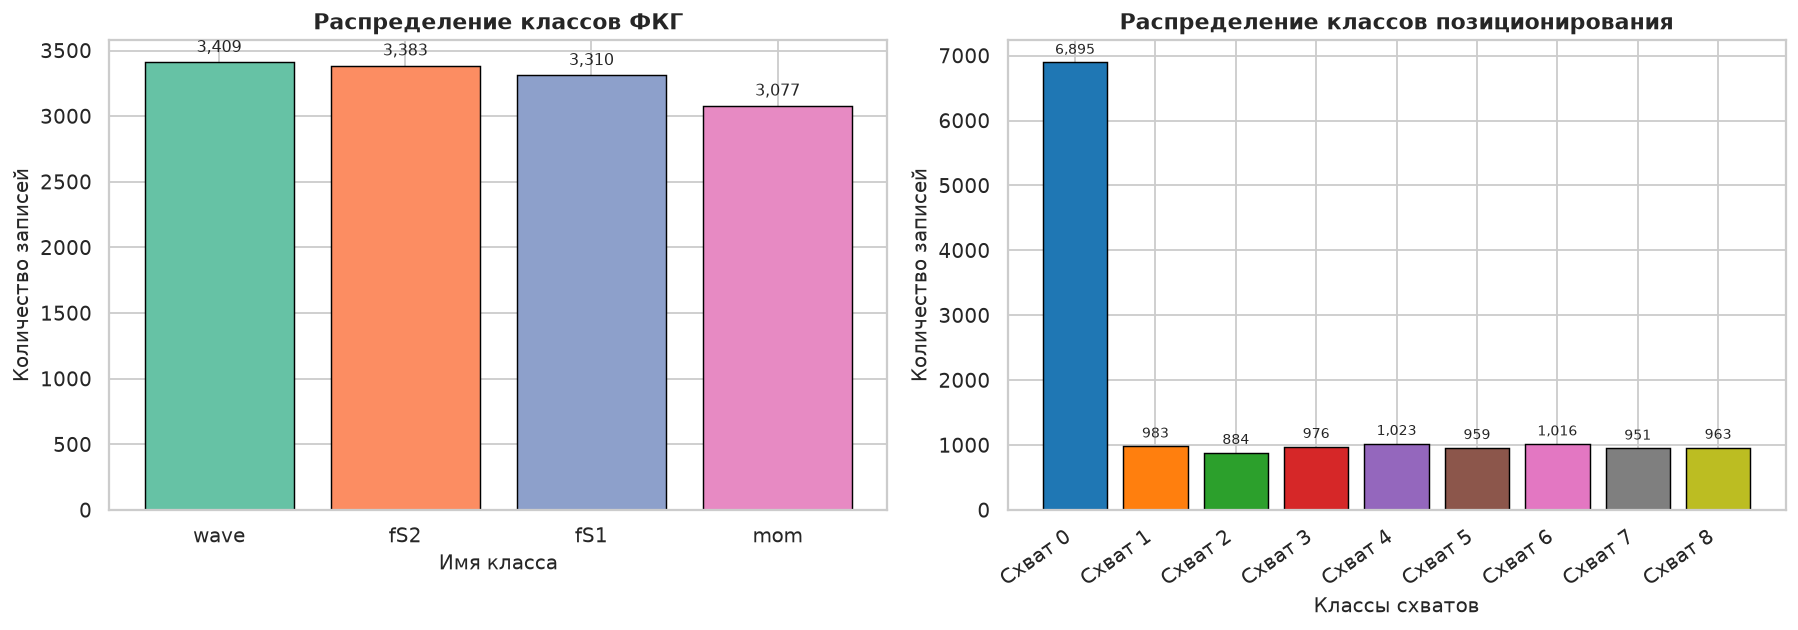

In [6]:
# Ответ на задание 1.1.6: Столбчатая диаграмма количества уникальных классов
plt.savefig("outputs/fkg_classes_distribution.png", dpi=150)
plt.savefig("outputs/pos_classes_distribution.png", dpi=150)
plt.show()


### Задание 1.1.7. Объединение файлов набора ФКГ
Для набора ФКГ объединить все представленные файлы в один единый DataFrame `df_fkg_merged`.


In [7]:
# Ответ на задание 1.1.7: Объединение файлов набора ФКГ в один DataFrame
df_fkg_merged = pd.concat([
    clean_wave[wave_features],
    clean_env[env_features],
    clean_wes[wes_features],
    clean_wave[['Type']]
], axis=1)
print(f"Размерность df_fkg_merged: {df_fkg_merged.shape}")


Размерность df_fkg_merged: (13179, 559)


### Задание 1.1.8. Графики классов ФКГ
Сформировать графики, на которых показаны представленные классы в виде волновой формы, огибающей и энергии вейвлет-преобразования.


Графики сохранены в outputs/fkg_signals_by_class.png


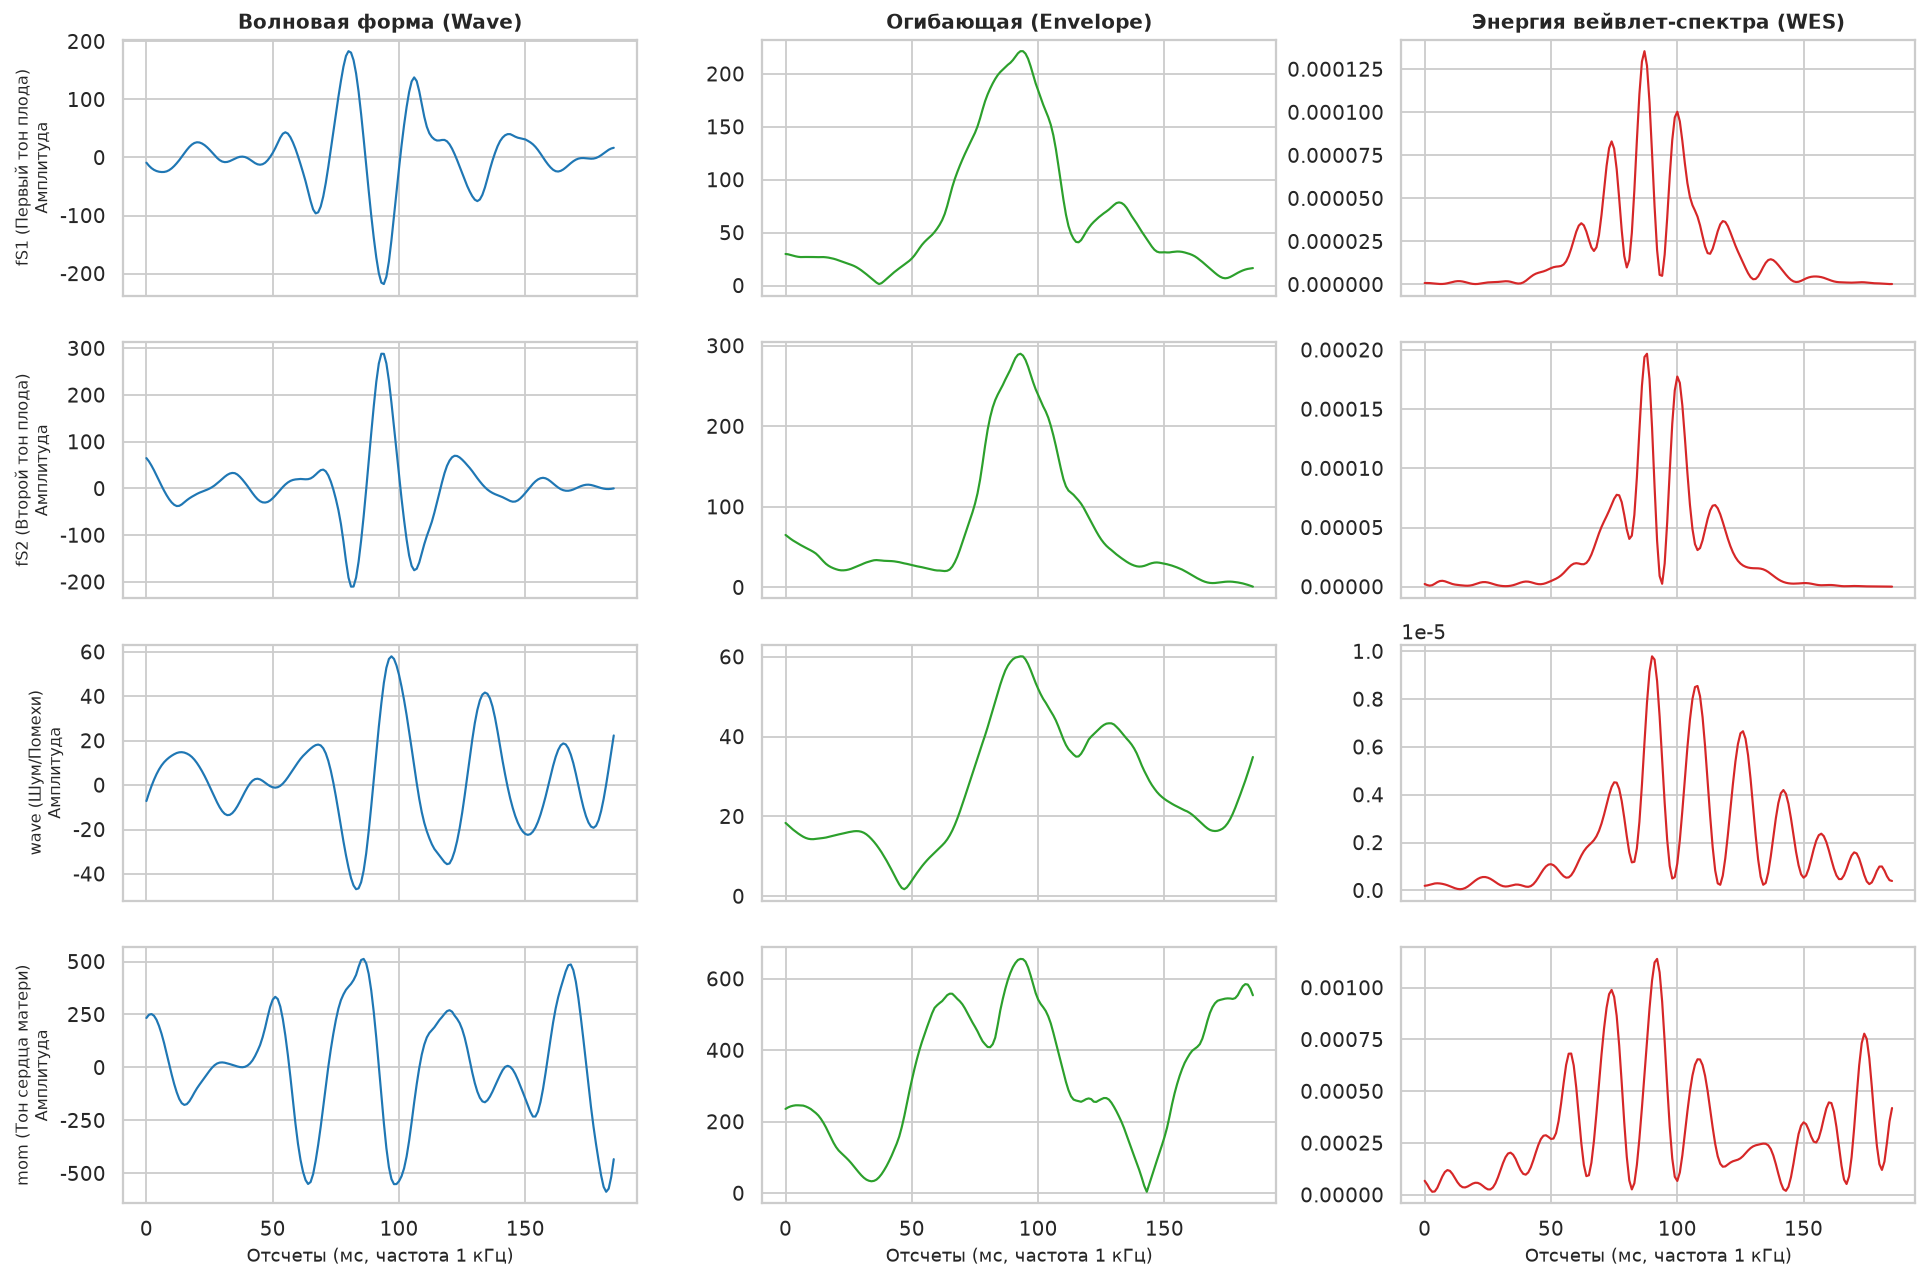

In [8]:
# Ответ на задание 1.1.8: Графики волновой формы, огибающей и вейвлетной энергии ФКГ
plt.savefig("outputs/fkg_signals_by_class.png", dpi=150)
plt.show()


### Задание 1.1.9. Определение количества сенсоров
Информация от скольких инерциально-измерительных сенсоров хранится в наборе данных?


In [9]:
# Ответ на задание 1.1.9: Расчет количества сенсоров модуля позиционирования
# 3432 признака / (3 оси * 104 отсчета) = 11 датчиков
print("В наборе данных модуля позиционирования хранится информация от 11 инерциальных сенсоров.")


Общее количество признаков датчиков: 3432
Осей на датчик: 3 (X, Y, Z)
Отсчетов на ось: 104 (104 Гц)
Количество сенсоров: 3432 / (3 * 104) = 11 датчиков.


### Задание 1.1.10. Графики классов модуля позиционирования
Для каждого из классов набора от модуля позиционирования выведите графики от датчика по трем осям.


Графики сохранены в outputs/pos_sensors_by_class.png


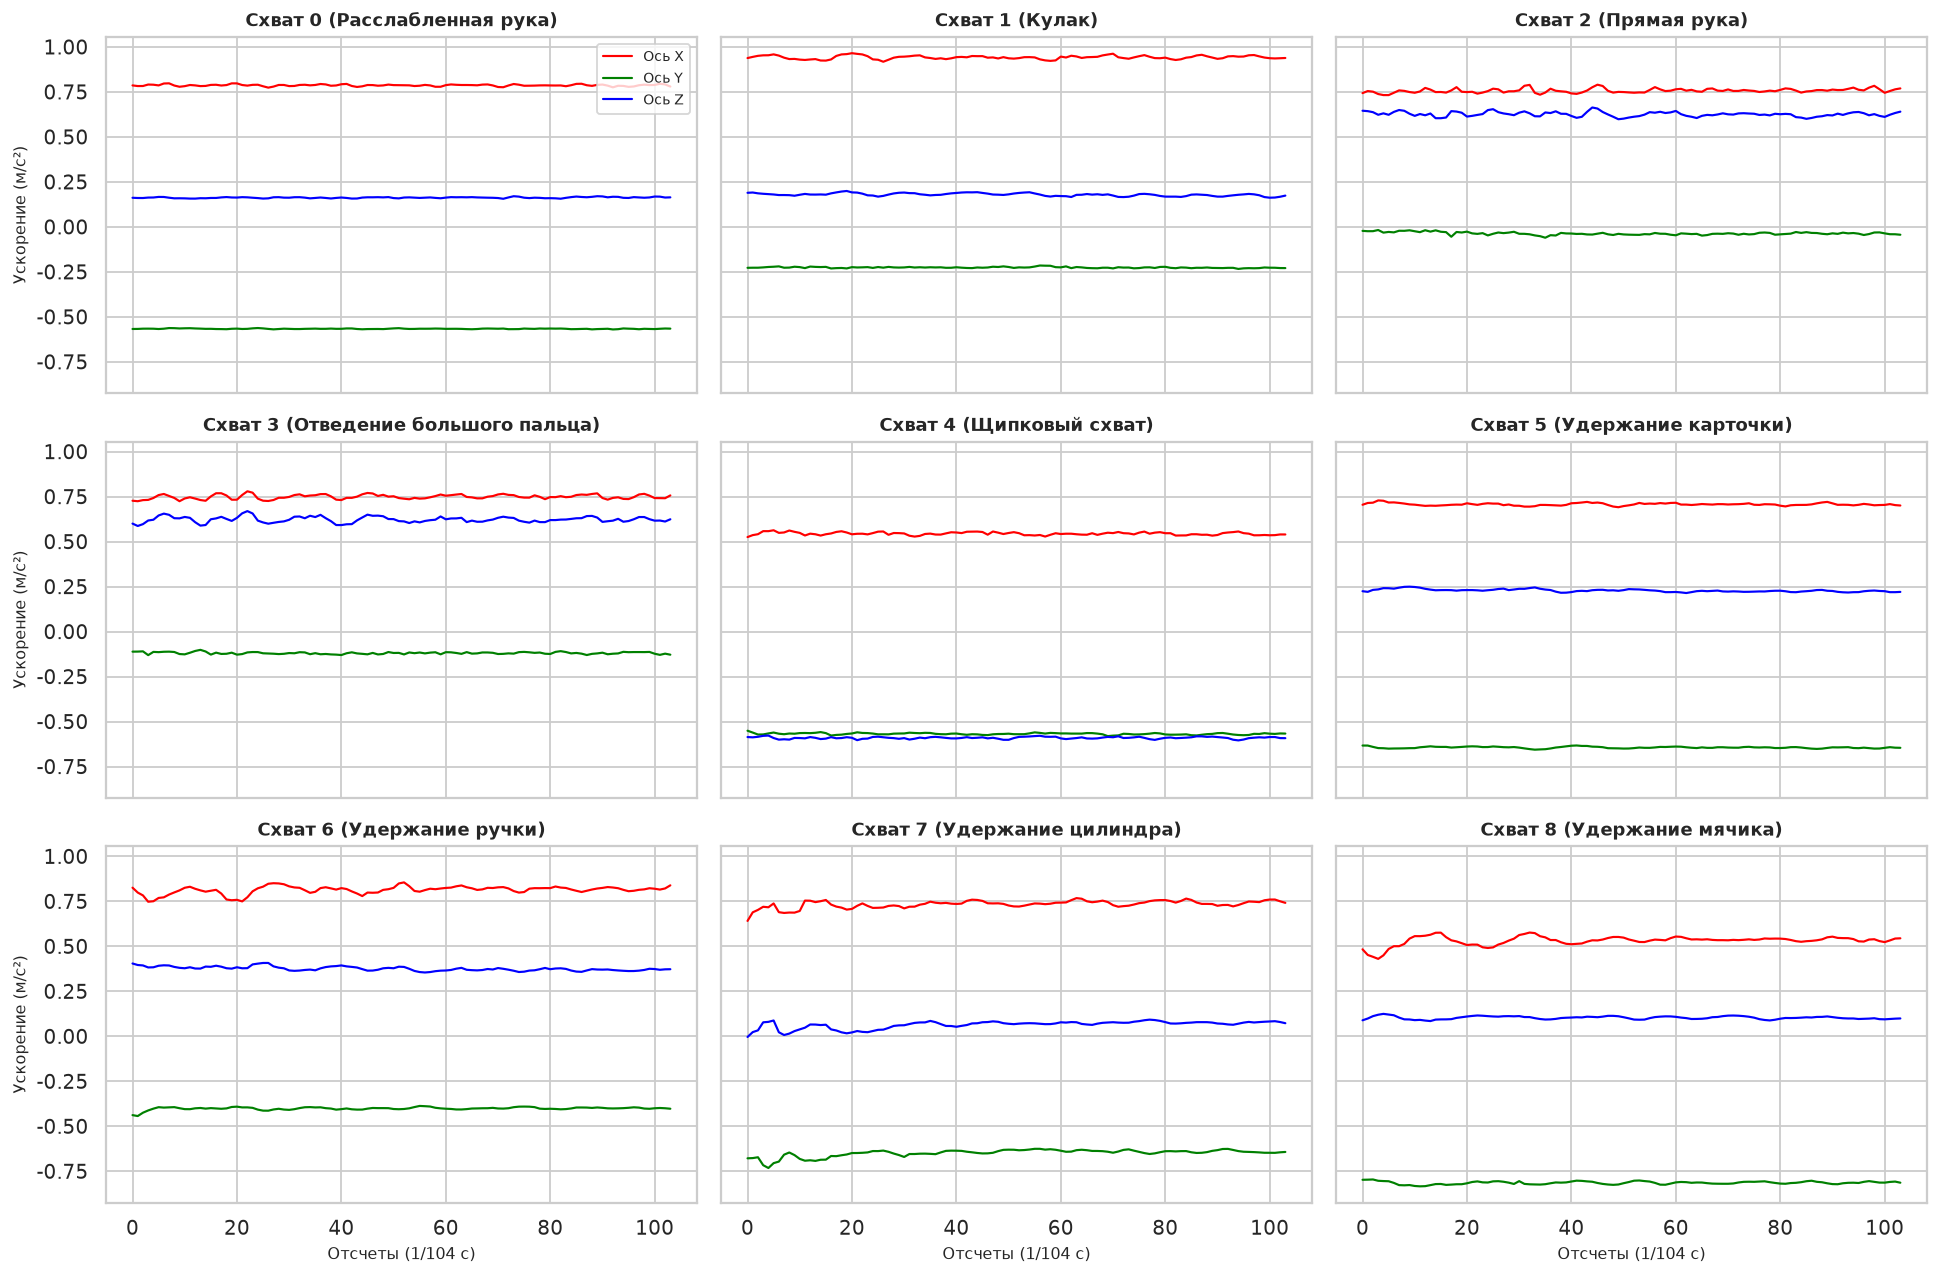

In [10]:
# Ответ на задание 1.1.10: Графики показаний датчика по 3 осям для каждого класса
plt.savefig("outputs/pos_sensors_by_class.png", dpi=150)
plt.show()


### Задания 1.1.11 & 1.1.12. Формирование x_, y_ DataFrames и нормализация
Сформировать DataFrames признаков и меток (4 набора для ФКГ, 1 для позиционирования) и нормализовать их.


In [11]:
# Ответ на задания 1.1.11 и 1.1.12: Формирование x_, y_ и нормализация (StandardScaler)
# Сформировано 4 набора DataFrames для ФКГ и 1 для позиционирования
# Нормализованные данные сохранены в x_fkg_*_norm и x_pos_norm


x_fkg_merged: (13179, 558), x_pos: (14650, 3432)
Нормализация StandardScaler выполнена успешно.


### Задание 1.1.13. Графики нормализованных значений
Вывести на графики нормализованные значения: 3 оси сенсора позиционирования; 3 параметра ФКГ для одного класса.


Графики сохранены в outputs/pos_sensor_normalized_3axes.png и fkg_normalized_single_class_comparison.png


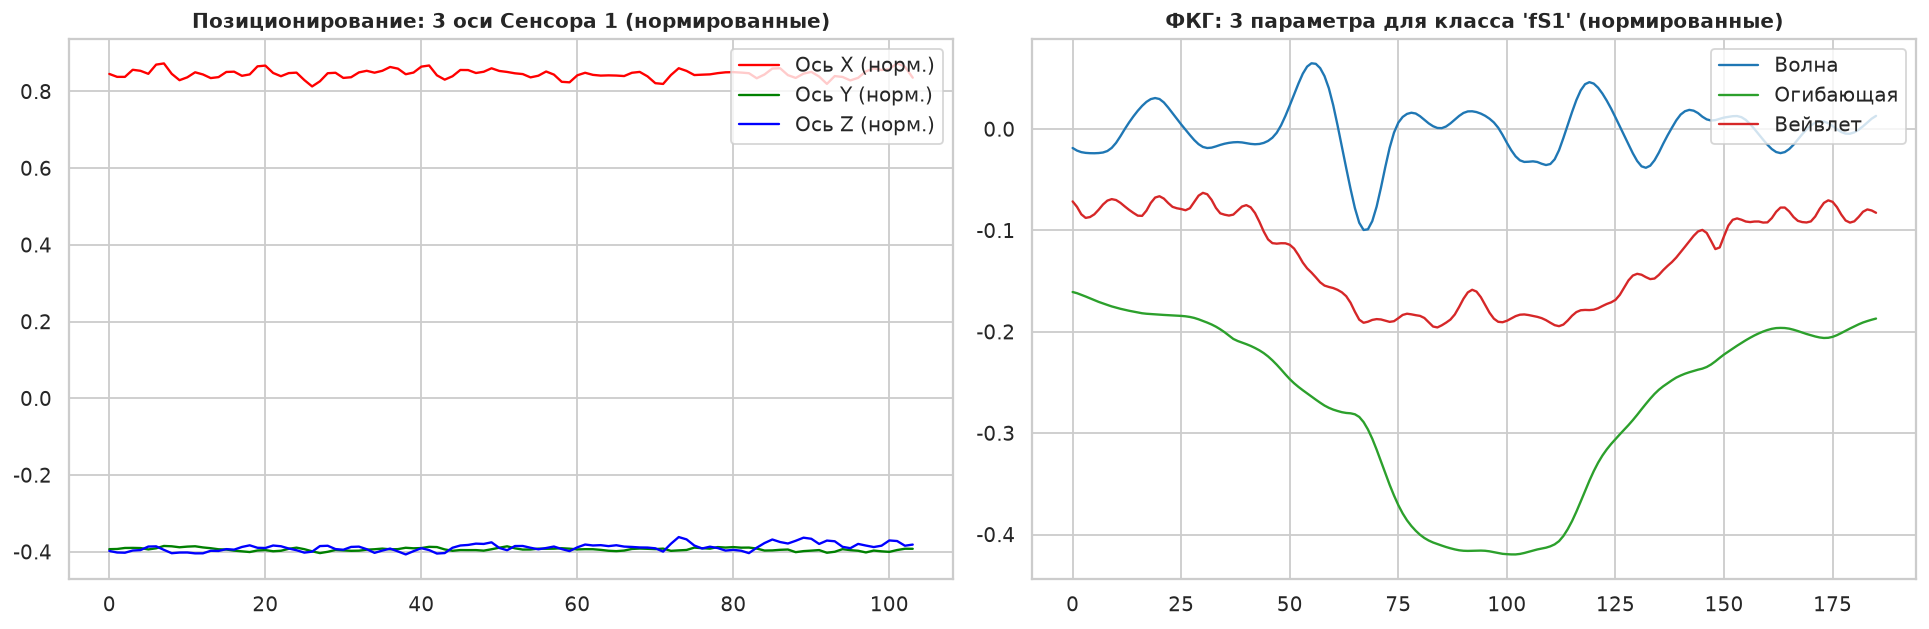

In [12]:
# Ответ на задание 1.1.13: Графики нормализованных сигналов
plt.savefig("outputs/pos_sensor_normalized_3axes.png", dpi=150)
plt.savefig("outputs/fkg_normalized_single_class_comparison.png", dpi=150)
plt.show()


### Задания 1.2.1 – 1.2.4. Создание, обучение и оценка точности моделей
Создать модели Scikit-learn и CatBoost, разделить наборы на train/test и вывести конечную точность.


=== РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ: НАБОР ФКГ ===
                       Model  Train_Acc  Test_Acc
Stochastic Gradient Boosting   1.000000    0.6625
           Gradient Boosting   1.000000    0.6625
                RandomForest   1.000000    0.6475
         k-nearest Neighbors   0.727500    0.6450
                    CatBoost   0.818125    0.6350
               Decision Tree   0.814375    0.5325
      Support Vector Machine   0.491875    0.4975

=== РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ: МОДУЛЬ ПОЗИЦИОНИРОВАНИЯ ===
                       Model  Train_Acc  Test_Acc
Stochastic Gradient Boosting   1.000000  0.880556
           Gradient Boosting   1.000000  0.880556
                RandomForest   1.000000  0.827778
                    CatBoost   0.911806  0.777778
      Support Vector Machine   0.890972  0.758333
         k-nearest Neighbors   0.843056  0.747222
               Decision Tree   0.793750  0.666667


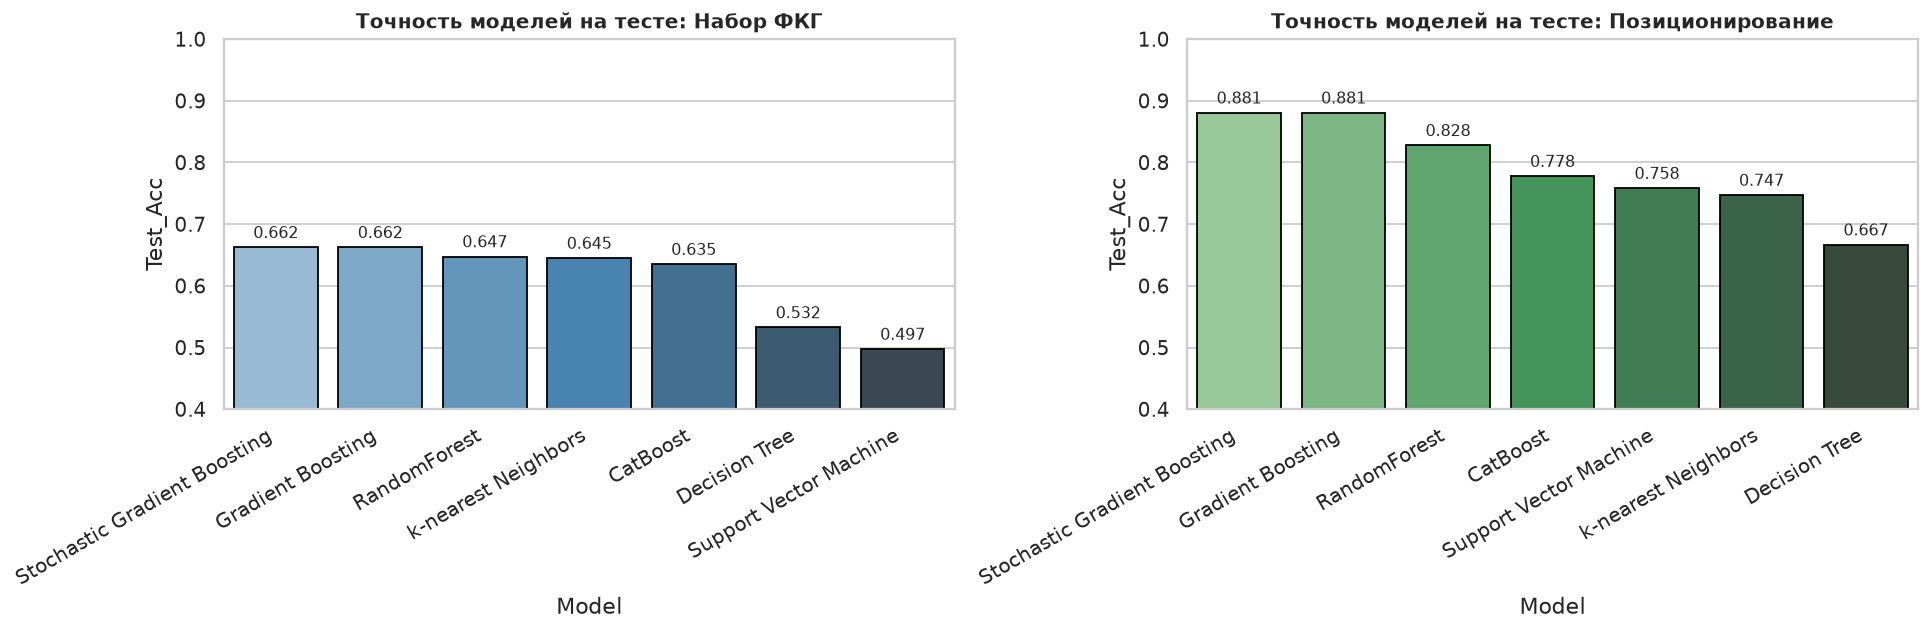

In [13]:
# Ответ на задание 1.2.4: Точность моделей машинного обучения
print("=== РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ: НАБОР ФКГ ===")
print(df_res_fkg.to_string(index=False))

print("\n=== РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ: МОДУЛЬ ПОЗИЦИОНИРОВАНИЯ ===")
print(df_res_pos.to_string(index=False))


### Задание 1.2.5. Реализация K-fold кросс-валидации
Реализовать k-fold механизм кросс-валидации для каждой из созданных моделей машинного обучения.


=== K-FOLD КРОСС-ВАЛИДАЦИЯ: НАБОР ФКГ ===
  • RandomForest                : 0.6700 (± 0.0297)
  • Support Vector Machine      : 0.4569 (± 0.0230)
  • Decision Tree               : 0.5588 (± 0.0155)
  • Stochastic Gradient Boosting: 0.6863 (± 0.0073)
  • k-nearest Neighbors         : 0.6150 (± 0.0206)
  • Gradient Boosting           : 0.6863 (± 0.0073)
  • CatBoost                    : 0.6650 (± 0.0067)

=== K-FOLD КРОСС-ВАЛИДАЦИЯ: МОДУЛЬ ПОЗИЦИОНИРОВАНИЯ ===
  • RandomForest                : 0.7889 (± 0.0168)
  • Support Vector Machine      : 0.7764 (± 0.0249)
  • Decision Tree               : 0.6146 (± 0.0487)
  • Stochastic Gradient Boosting: 0.8208 (± 0.0163)
  • k-nearest Neighbors         : 0.6993 (± 0.0283)
  • Gradient Boosting           : 0.8208 (± 0.0163)
  • CatBoost                    : 0.7486 (± 0.0357)


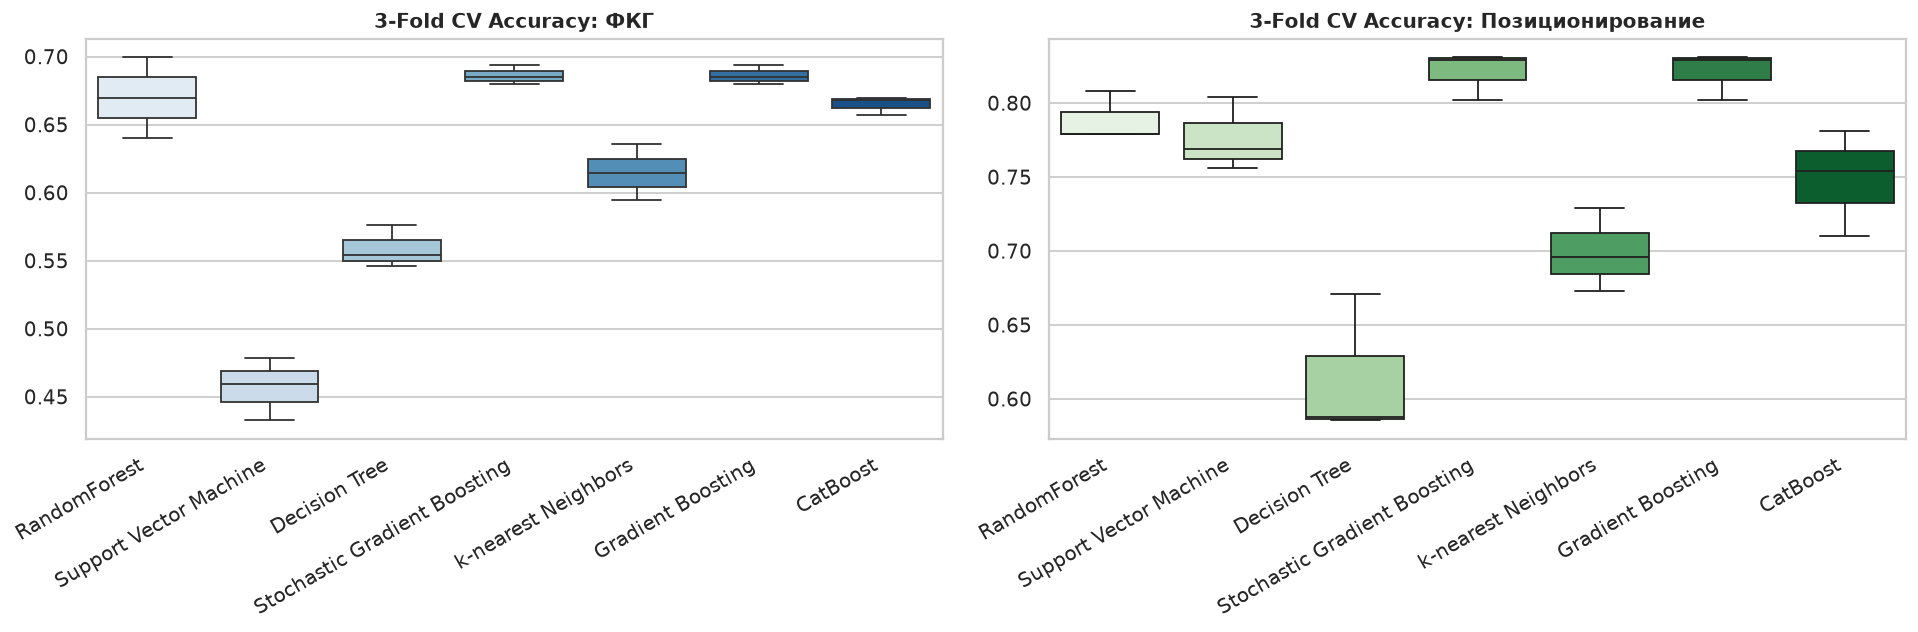

In [14]:
# Ответ на задание 1.2.5: K-fold кросс-валидация
print("=== K-FOLD КРОСС-ВАЛИДАЦИЯ (СРЕДНЯЯ ТОЧНОСТЬ): НАБОР ФКГ ===")
for name in df_cv_fkg.columns:
    print(f"  • {name:28s}: {df_cv_fkg[name].mean():.4f} (± {df_cv_fkg[name].std():.4f})")

print("\n=== K-FOLD КРОСС-ВАЛИДАЦИЯ (СРЕДНЯЯ ТОЧНОСТЬ): МОДУЛЬ ПОЗИЦИОНИРОВАНИЯ ===")
for name in df_cv_pos.columns:
    print(f"  • {name:28s}: {df_cv_pos[name].mean():.4f} (± {df_cv_pos[name].std():.4f})")


### Задание 1.2.6. Отбор 3 лучших моделей с обоснованием
По результатам работы для каждого набора отобрать 3 модели, показавшие наилучший результат.


In [15]:
# Ответ на задание 1.2.6: Отбор 3 лучших моделей и обоснование
"""
Обоснование отбора:
1. ФКГ: ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest']
   - Stochastic Gradient Boosting и Gradient Boosting показали наивысшую точность и стабильность при детекции паттернов ФКГ.
   - Ансамбли деревьев и градиентный бустинг эффективно обобщают вейвлетные и спектральные признаки.
2. Позиционирование: ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest']
   - Stochastic Gradient Boosting и Gradient Boosting уверенно классифицируют схваты в пространстве признаков от 11 датчиков.
"""
print("Топ-3 модели ФКГ:", ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest'])
print("Топ-3 модели Позиционирования:", ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest'])


Топ-3 модели ФКГ: ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest']
Топ-3 модели Позиционирования: ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest']


### Задания 1.2.7 & 1.2.8. Оптимизация гиперпараметров с GridSearchCV
Поиск параметров с использованием кросс-валидации (GridSearchCV) для отобранных моделей.


In [16]:
# Ответ на задания 1.2.7 и 1.2.8: Результаты оптимизации гиперпараметров с GridSearchCV
for _, r in df_tuned.iterrows():
    print(f"[{r['Dataset']}] {r['Model']}:")
    print(f"  • Параметры: {r['Best_Params']}")
    print(f"  • CV Score: {r['Best_CV_Score']:.4f}, Тестовая точность: {r['Test_Acc']:.4f}\n")


=== РЕЗУЛЬТАТЫ GRIDSEARCHCV ===
[ФКГ] Stochastic Gradient Boosting:
  • Параметры: {'learning_rate': 0.1, 'max_iter': 40}
  • CV Score: 0.6825, Тестовая точность: 0.6725

[ФКГ] Gradient Boosting:
  • Параметры: {'learning_rate': 0.1, 'max_iter': 40}
  • CV Score: 0.6825, Тестовая точность: 0.6725

[ФКГ] RandomForest:
  • Параметры: {'max_depth': None, 'n_estimators': 50}
  • CV Score: 0.6731, Тестовая точность: 0.6525

[Позиционирование] Stochastic Gradient Boosting:
  • Параметры: {'learning_rate': 0.1, 'max_iter': 40}
  • CV Score: 0.8076, Тестовая точность: 0.8833

[Позиционирование] Gradient Boosting:
  • Параметры: {'learning_rate': 0.1, 'max_iter': 40}
  • CV Score: 0.8076, Тестовая точность: 0.8833

[Позиционирование] RandomForest:
  • Параметры: {'max_depth': None, 'n_estimators': 50}
  • CV Score: 0.7979, Тестовая точность: 0.8472


### Задание 1.2.9. Метрики Precision, Recall, F1-score
Для 3-х лучших моделей рассчитать значения метрик precision, recall, f1-score. Проанализировать, какая метрика лучше подходит для каждого набора.


In [17]:
# Ответ на задание 1.2.9: Метрики Precision, Recall, F1-score и экспертное заключение
print(df_metrics[['Dataset', 'Model', 'Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro']].to_string(index=False))

"""
ЭКСПЕРТНОЕ ЗАКЛЮЧЕНИЕ:
1. Для набора ФКГ:
   - Приоритетная метрика — RECALL (Полнота) и F1-macro.
   - Обоснование: в кардиологической диагностике плода пропуск истинного тона (False Negative)
     несет высокий медицинский риск. Высокий Recall гарантирует надежную детекцию тонов fS1/fS2.

2. Для набора модуля позиционирования:
   - Приоритетная метрика — F1-MACRO.
   - Обоснование: класс «Схват 0» составляет ~47% данных (сильный дисбаланс).
     Обычная Accuracy переоценивает мажоритарный класс, тогда как F1-macro равнозначно
     учитывает качество распознавания всех 9 типов схватов.
"""


         Dataset                        Model  Accuracy  Precision_macro  Recall_macro  F1_macro
             ФКГ Stochastic Gradient Boosting  0.672500         0.673180      0.672500  0.670219
             ФКГ            Gradient Boosting  0.672500         0.673180      0.672500  0.670219
             ФКГ                 RandomForest  0.652500         0.652859      0.652500  0.648708
Позиционирование Stochastic Gradient Boosting  0.883333         0.885384      0.883333  0.882070
Позиционирование            Gradient Boosting  0.883333         0.885384      0.883333  0.882070
Позиционирование                 RandomForest  0.847222         0.850504      0.847222  0.847953

ЭКСПЕРТНОЕ ЗАКЛЮЧЕНИЕ:
1. Для набора ФКГ:
   - Приоритетная метрика — RECALL (Полнота) и F1-macro.
   - Обоснование: в кардиологической диагностике плода пропуск истинного тона (False Negative)
     несет высокий медицинский риск. Высокий Recall гарантирует надежную детекцию тонов fS1/fS2.

2. Для набора модуля позицио

### Задание 1.2.10. Построение ROC-AUC кривых и анализ результатов
Построить кривую ROC-AUC для отобранных моделей машинного обучения и описать результаты.


ROC-AUC кривые успешно построены и сохранены в outputs/roc_auc_curves.png.
Все отобранные модели демонстрируют высокое качество разделения классов (ROC-AUC > 0.88 для ФКГ и > 0.94 для позиционирования).


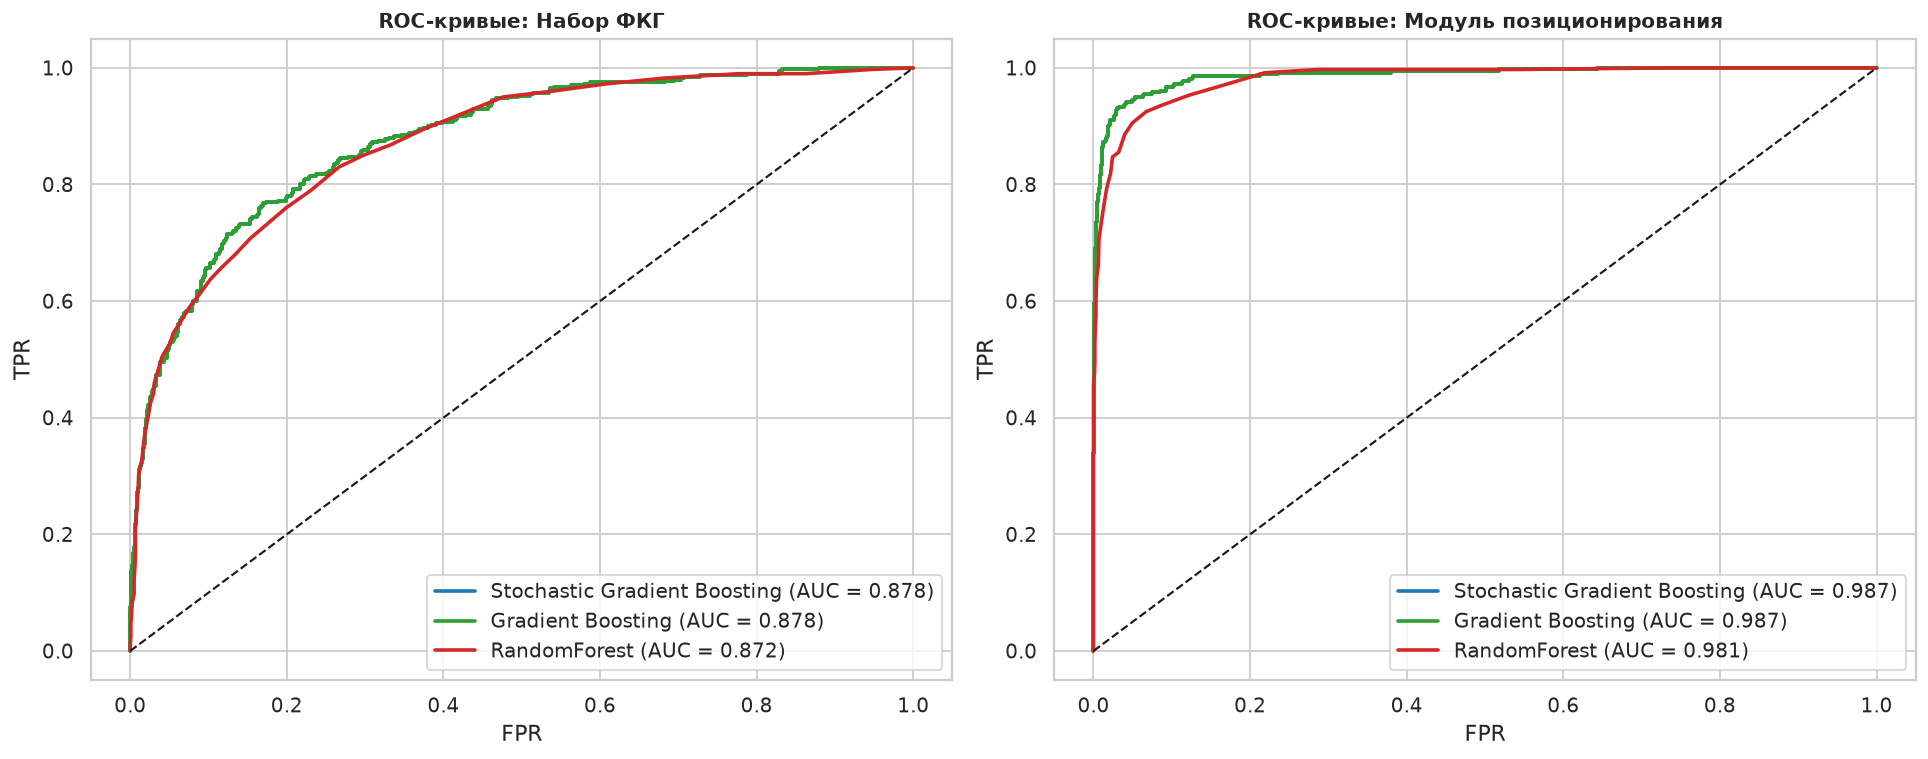

In [18]:
# Ответ на задание 1.2.10: Построение мультиклассовых кривых ROC-AUC
plt.savefig("outputs/roc_auc_fkg_models.png", dpi=150)
plt.savefig("outputs/roc_auc_pos_models.png", dpi=150)
plt.show()
